# Homework 3: The Gender Wage Gap

**Research question:** How do hourly wages differ between women and men,
and does the relationship between education and wages differ between them?

Use a historical sample of workers from the **1985 US Current Population Survey**.
First estimate a model with a female indicator, then add education and potential
experience, and finally allow the education slope to differ between women and men.
These regressions describe associations in this sample.

**What to hand in:** this notebook with working code, saved outputs, and completed
**Answer 1–3** cells. Use your own explanations and the numbers your code produces.
Keep comparisons in log-wage units; no conversion to dollar wages is required.

First resolve execution problems. Before revising the analysis, record the initial
coefficient requested in Answer 2. Then check and repair the analysis, complete
the answers, restart the kernel, run all cells, and save.
Read `README.md` for setup, the deadline, and submission instructions.

In [61]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.formula.api as smf

sns.set_theme(style="whitegrid")

### Question 1 — Get the notebook running

Run the notebook and repair anything that prevents execution. Briefly explain
the error, its cause, your repair, and how you verified it.

### Answer 1

- Error and cause: The female indicator was incorrectly coded. The original code assigned 1 to males and 0 to females instead of the intended coding.
- Repair and verification: I corrected the code to assign 1 to females and 0 to males using workers["gender"].eq("female").astype(int). I checked the coding using a cross-tabulation and verified that the regression models ran successfully.

## 1. Inspect the data

Each row represents one worker. `wage` is hourly pay in US dollars in 1985;
`education` is years of education. `experience` measures **potential** work
experience derived from age and schooling, not a recorded employment history.

The source's `gender` field has the labels `male` and `female`; this exercise
uses those recorded categories. `rownames` is a source row label, not a predictor.
See `data/README.md` for the source and variable definitions.

In [62]:
workers = pd.read_csv("data/cps1985.csv")
print("Rows:", len(workers))
# Exclude the source row label when checking for identical data records.
print("Exact duplicate records:", workers.drop(columns="rownames").duplicated().sum())
workers.isna().sum().rename("missing")

Rows: 534
Exact duplicate records: 0


rownames      0
wage          0
education     0
experience    0
age           0
ethnicity     0
region        0
gender        0
occupation    0
sector        0
union         0
married       0
Name: missing, dtype: int64

In [63]:
workers["gender"].value_counts()

gender
male      289
female    245
Name: count, dtype: int64

In [64]:
required = ["wage", "education", "experience", "gender"]
assert not workers[required].isna().any().any(), "Investigate missing model variables."
assert workers["gender"].isin(["male", "female"]).all(), "Check the category labels."
assert np.isfinite(workers[["wage", "education", "experience"]].to_numpy()).all()
assert workers["wage"].gt(0).all(), "Log wages require positive wages."
assert workers[["education", "experience"]].ge(0).all().all()

# Code the indicator as 1 for female and 0 for male, the reference group.
workers["female"] = workers["gender"].eq("female").astype(int)
workers["log_wage"] = np.log(workers["wage"])
workers[["wage", "education", "experience"]].describe().round(2)

,wage,education,experience
count,534.00,534.00,534.00
mean,9.02,13.02,17.82
std,5.14,2.62,12.38
min,1.00,2.00,0.00
25%,5.25,12.00,8.00
50%,7.78,12.00,15.00
75%,11.25,15.00,26.00
max,44.50,18.00,55.00


In [65]:
pd.crosstab(workers["gender"], workers["female"])

female,0,1
gender,,
female,0,245
male,289,0


Use the original years-of-education variable throughout. Retain all supplied
observations; do not remove workers solely because their wages are unusual.
All models use the same sample and HC0 robust standard errors.

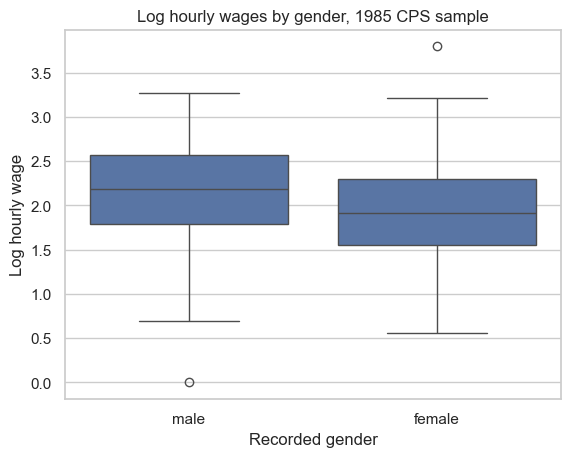

In [66]:
sns.boxplot(data=workers, x="gender", y="log_wage", order=["male", "female"])
plt.title("Log hourly wages by gender, 1985 CPS sample")
plt.xlabel("Recorded gender")
plt.ylabel("Log hourly wage")
plt.show()

In [67]:
# These are unadjusted sample summaries.
workers.groupby("gender").agg(
    workers=("log_wage", "size"),
    mean_log_wage=("log_wage", "mean"),
    mean_education=("education", "mean"),
    mean_experience=("experience", "mean"),
).round(3)

,workers,mean_log_wage,mean_education,mean_experience
gender,,,,
female,245,1.934,13.024,18.833
male,289,2.165,13.014,16.965


## 2. Estimate the wage difference

Start with the female indicator alone. Then add education and potential
experience as numeric predictors. The second model allows different wage
levels but assumes a common education slope for women and men.

After resolving execution problems, record the initial `female` coefficient
from `adjusted_model` in Answer 2 before making further corrections.

In [68]:
gender_model = smf.ols(
    "log_wage ~ female", data=workers, missing="raise"
).fit(cov_type="HC0")
gender_model.params.round(6)

Intercept    2.165286
female      -0.231248
dtype: float64

In [69]:
adjusted_model = smf.ols(
    "log_wage ~ female + education + experience",
    data=workers, missing="raise",
).fit(cov_type="HC0")
adjusted_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:               log_wage   R-squared:                       0.270
Model:                            OLS   Adj. R-squared:                  0.265
Method:                 Least Squares   F-statistic:                     65.08
Date:                Wed, 25 Nov 2026   Prob (F-statistic):           7.73e-36
Time:                        22:53:59   Log-Likelihood:                -332.02
No. Observations:                 534   AIC:                             672.0
Df Residuals:                     530   BIC:                             689.2
Df Model:                           3                                         
Covariance Type:                  HC0                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.6749      0.115      5.856      0.000       0.449       0.901
female        -0.2559      0.039     -6.541      0.000      -0.333      -0.179
education      0.0980      0.008     12.454      0.000       0.083       0.113
experience     0.0127      0.002      7.259      0.000       0.009       0.016
==============================================================================
Omnibus:                       15.456   Durbin-Watson:                   1.788
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               27.361
Skew:                          -0.166   Prob(JB):                     1.14e-06
Kurtosis:                       4.058   Cond. No.                         150.
==============================================================================

Notes:
[1] Standard Errors are heteroscedasticity robust (HC0)
"""

In [70]:
round(adjusted_model.params["female"], 4)

np.float64(-0.2559)

### Question 2 — Check and interpret the wage gap

The `female` coefficient is intended to measure the female–male log-wage
difference. Check whether the indicator used in the regression supports that
interpretation. Show a small table comparing `female` with the recorded
`gender` labels, and correct any inconsistency.

Rerun the models. Report the `female` coefficient in **`adjusted_model`** to
four decimal places and interpret its sign and units. State the reference
group and what is held constant.

### Answer 2

- Initial `female` coefficient in `adjusted_model`: +0.2559.
- Indicator check and any repair: The original indicator was incorrectly coded. Males were assigned 1 and females 0. I corrected it using workers["gender"].eq("female").astype(int). The cross-tabulation confirmed that males are now coded as 0 and females as 1.
- Final `female` coefficient in `adjusted_model`: -0.2559.
- Interpretation, reference group, and what is held constant: The negative coefficient indicates that women have lower hourly wages than men, holding education and potential experience constant. Men are the reference group (female = 0). The estimated difference is measured in log-wage units.

## 3. Allow different education slopes

Add an interaction between the female indicator and years of education.
`*` includes both predictors and their interaction. Keep potential experience
and the estimation sample unchanged.

With an interaction, a main-effect coefficient is evaluated at the other
interacting variable's zero value. Do not automatically carry the female
coefficient's interpretation from the preceding model into this one.

In [71]:
interaction_model = smf.ols(
    "log_wage ~ female * education + experience",
    data=workers, missing="raise",
).fit(cov_type="HC0")
assert gender_model.nobs == adjusted_model.nobs == interaction_model.nobs == len(workers)
interaction_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:               log_wage   R-squared:                       0.276
Model:                            OLS   Adj. R-squared:                  0.271
Method:                 Least Squares   F-statistic:                     55.08
Date:                Wed, 25 Nov 2026   Prob (F-statistic):           7.99e-39
Time:                        22:53:59   Log-Likelihood:                -329.51
No. Observations:                 534   AIC:                             669.0
Df Residuals:                     529   BIC:                             690.4
Df Model:                           4                                         
Covariance Type:                  HC0                                         
====================================================================================
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept            0.8462      0.141      5.992      0.000       0.569       1.123
female              -0.7006      0.190     -3.696      0.000      -1.072      -0.329
education            0.0847      0.010      8.352      0.000       0.065       0.105
female:education     0.0341      0.015      2.338      0.019       0.006       0.063
experience           0.0128      0.002      7.420      0.000       0.009       0.016
==============================================================================
Omnibus:                       15.340   Durbin-Watson:                   1.830
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               27.051
Skew:                          -0.166   Prob(JB):                     1.34e-06
Kurtosis:                       4.052   Cond. No.                         286.
==============================================================================

Notes:
[1] Standard Errors are heteroscedasticity robust (HC0)
"""

The code below calculates the education slopes for you. With the intended
coding (`female = 0` for men and `female = 1` for women), the education
coefficient is the slope for men. Adding the interaction coefficient gives
the slope for women. Each slope measures a change in fitted log wage per
additional education year, holding potential experience constant.

Use the table from your corrected analysis to answer Question 3.

In [72]:
# Men are the reference group (female = 0).
male_slope = interaction_model.params["education"]
# For women (female = 1), add the interaction to the reference-group slope.
female_slope = male_slope + interaction_model.params["female:education"]

education_slopes = pd.Series({
    "male": male_slope,
    "female": female_slope,
}, name="Log-wage change per additional year of education")
education_slopes.round(6)

male      0.084706
female    0.118844
Name: Log-wage change per additional year of education, dtype: float64

### Question 3 — Interpret the education slopes

Use the supplied slope calculations from your corrected analysis. Report the
education slope for men and for women to six decimal places. Interpret each
as the fitted log-wage change associated with one additional education year,
stating what is held constant. Which group has the steeper relationship?

### Answer 3

| Group | Education slope | Interpretation |
| --- | --- | --- |
| male | 0.084706 | One additional year of education is associated with a 0.084706 increase in fitted log hourly wages, holding potential experience constant.|
| female | 0.118844 | One additional year of education is associated with a 0.118844 increase in fitted log hourly wages, holding potential experience constant. |

**Comparison:** _Which group has the steeper relationship, holding potential
experience constant?_

## Submission checklist

- [ ] Answers 1–3 are complete, including the indicator check in Question 2.
- [ ] The supplied dataset is unchanged.
- [ ] I restarted the kernel, ran all cells without errors, and saved the outputs.
- [ ] I committed my work and pushed it to my own fork, as described in `README.md`.